# 03 — Modelagem: LightGBM × XGBoost e os candidatos A / B / C
**Conjuntos de variáveis** (decisão 1.10): **A** sem valores do contrato · **B** com o **percentil** dos valores no mês · **C** com os valores brutos (só referência).
**Modelos:** baseline logístico, LightGBM e XGBoost, com as mesmas variáveis, os mesmos splits, o mesmo Optuna (nº de trials e seed) e o nº de árvores definido no CV.
**Fluxo:** (1) tuning no treino (CV agrupado por cliente) → (2) avaliação na validação e no teste → (3) LGBM × XGB no conjunto B → (4) critérios de adoção do B → (5) target DPD > 30 e pesos de classe.
O **limiar** de cada modelo é o de máximo F1 **na validação**. O **teste** não entra em tuning, limiar ou escolha do algoritmo; ele só confirma (e entra no critério de adoção do B, definido antes).

In [1]:
import sys, json, time, warnings; sys.path.insert(0, '../src')
warnings.filterwarnings('ignore', module='xgboost|sklearn|lightgbm|optuna')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from IPython.display import display
from scipy.stats import spearmanr
import features as ft, train as tr
from config import GERADOS, OUTPUTS
from evaluate import metricas, limiar_max_f1, delong, bootstrap_pareado, psi

pd.set_option('display.width', 220, 'display.max_columns', 60)
sns.set_theme(style='whitegrid')
FIG, TAB = OUTPUTS / 'figures', OUTPUTS / 'tables'
MOD = GERADOS / 'modelos'; MOD.mkdir(exist_ok=True)
N_TRIALS, N_FOLDS = 25, 5

b = pd.read_parquet(GERADOS / 'base_modelagem.parquet'); bs = pd.read_parquet(GERADOS / 'base_submissao_features.parquet')
SPL = ['treino', 'valid', 'teste']
sp = {s: b[b.split == s].reset_index(drop=True) for s in SPL}
Y = {s: sp[s].target_dpd5.astype(int) for s in SPL}
cats = tr.categorias_do_treino(sp['treino'])
CONJ = ['A', 'B', 'C']
XS = {c: {**{s: tr.preparar(sp[s], ft.FEATURES[c], cats) for s in SPL}, 'sub': tr.preparar(bs, ft.FEATURES[c], cats)} for c in CONJ}
print({s: (len(sp[s]), round(Y[s].mean(), 4)) for s in SPL}, '| submissão:', len(bs))

C:\Projetos\dsaccelerator-tcc\notebooks\../src\train.py:31: UserWarning: tipo_renda: categorias fora do treino viraram nulo: ['Empresário']
  warnings.warn(f"{c}: categorias fora do treino viraram nulo: {sorted(novas)}")


C:\Projetos\dsaccelerator-tcc\notebooks\../src\train.py:31: UserWarning: tipo_renda: categorias fora do treino viraram nulo: ['Empresário']
  warnings.warn(f"{c}: categorias fora do treino viraram nulo: {sorted(novas)}")


{'treino': (62580, np.float64(0.2531)), 'valid': (22255, np.float64(0.1759)), 'teste': (14026, np.float64(0.1747))} | submissão: 50000


C:\Projetos\dsaccelerator-tcc\notebooks\../src\train.py:31: UserWarning: tipo_renda: categorias fora do treino viraram nulo: ['Empresário']
  warnings.warn(f"{c}: categorias fora do treino viraram nulo: {sorted(novas)}")


## 1. Tuning (Optuna) e treino

In [2]:
def tuning(alg, conj):
    f = MOD / f'tuning_{alg}_{conj}.json'
    if f.exists(): return json.loads(f.read_text())
    t0 = time.time()
    p, n, folds = tr.tunar(alg, XS[conj]['treino'], Y['treino'], sp['treino'].id_cliente, N_TRIALS, N_FOLDS)
    r = {'params': p, 'n_arvores': n, 'pr_auc_folds': folds.tolist(), 'segundos_tuning': time.time() - t0}
    f.write_text(json.dumps(r)); return r

def prever(m, X, conj_alg):
    return m.predict_proba(X)[:, 1]

T, MODELOS, S, TEMPO = {}, {}, {}, {}
for conj in CONJ:
    for alg in ['lgbm', 'xgb']:
        T[alg, conj] = tuning(alg, conj)
        m, seg = tr.treinar(alg, T[alg, conj]['params'], T[alg, conj]['n_arvores'], XS[conj]['treino'], Y['treino'])
        t0 = time.perf_counter(); pt = m.predict_proba(XS[conj]['teste'])[:, 1]; inf = time.perf_counter() - t0
        MODELOS[alg, conj] = m
        S[alg, conj] = {'valid': m.predict_proba(XS[conj]['valid'])[:, 1], 'teste': pt, 'sub': m.predict_proba(XS[conj]['sub'])[:, 1]}
        TEMPO[alg, conj] = {'tuning_s': T[alg, conj]['segundos_tuning'], 'treino_s': seg, 'inferencia_teste_s': inf}
    # baseline logístico (mesmas variáveis)
    cat_obj = lambda X: X.astype({c: object for c in ft.CATEGORICAS if c in X})
    lr = tr.baseline_logistico(XS[conj]['treino'], Y['treino']); MODELOS['lr', conj] = lr
    S['lr', conj] = {s: lr.predict_proba(cat_obj(XS[conj][s]))[:, 1] for s in ['valid', 'teste', 'sub']}
print('modelos treinados:', len(MODELOS))

modelos treinados: 9


## 2. Avaliação na validação e no teste (limiar de máximo F1 na validação)

In [3]:
NOMES = {'lr': 'Logística', 'lgbm': 'LightGBM', 'xgb': 'XGBoost'}
LIM, linhas = {}, []
for (alg, conj), sc in S.items():
    LIM[alg, conj] = limiar_max_f1(Y['valid'], sc['valid'])
    for s in ['valid', 'teste']:
        linhas.append({'modelo': NOMES[alg], 'conj': conj, 'split': s, **metricas(Y[s], sc[s], LIM[alg, conj])})
res = pd.DataFrame(linhas)
cols = ['recall', 'f1', 'precision', 'f2', 'auc', 'gini', 'ks', 'pr_auc']
for s in ['valid', 'teste']:
    print(f'--- {s} ---'); display(res[res.split == s].set_index(['modelo', 'conj'])[cols + ['taxa_aprovacao']].round(4))
res.to_csv(TAB / 'nb03_metricas_modelos.csv', index=False)

--- valid ---


,,recall,f1,precision,f2,auc,gini,ks,pr_auc,taxa_aprovacao
modelo,conj,,,,,,,,,
LightGBM,A,0.3862,0.4786,0.6292,0.4185,0.6992,0.3983,0.3467,0.4414,0.8920
XGBoost,A,0.3982,0.4766,0.5935,0.4263,0.6957,0.3913,0.3404,0.4377,0.8820
Logística,A,0.5543,0.3278,0.2327,0.4343,0.6124,0.2247,0.1724,0.2850,0.5810
LightGBM,B,0.3880,0.4731,0.6059,0.4181,0.7039,0.4079,0.3433,0.4379,0.8874
XGBoost,B,0.4156,0.4781,0.5628,0.4385,0.7051,0.4101,0.3502,0.4393,0.8701
Logística,B,0.4089,0.3432,0.2957,0.3799,0.6247,0.2493,0.2010,0.3082,0.7567
LightGBM,C,0.4010,0.4739,0.5791,0.4273,0.7067,0.4134,0.3447,0.4380,0.8782
XGBoost,C,0.4130,0.4800,0.5730,0.4375,0.7087,0.4173,0.3496,0.4405,0.8732
Logística,C,0.4278,0.3551,0.3035,0.3954,0.6323,0.2646,0.2182,0.3226,0.7520


--- teste ---


,,recall,f1,precision,f2,auc,gini,ks,pr_auc,taxa_aprovacao
modelo,conj,,,,,,,,,
LightGBM,A,0.3884,0.4771,0.6182,0.4196,0.6942,0.3885,0.3437,0.4346,0.8902
XGBoost,A,0.4011,0.4767,0.5876,0.4282,0.6898,0.3796,0.3442,0.4327,0.8807
Logística,A,0.5435,0.3198,0.2265,0.4246,0.6004,0.2008,0.1668,0.2797,0.5808
LightGBM,B,0.3896,0.4769,0.6145,0.4204,0.7032,0.4063,0.3486,0.4374,0.8892
XGBoost,B,0.4109,0.4767,0.5676,0.4349,0.7034,0.4068,0.3499,0.4408,0.8735
Logística,B,0.3856,0.3290,0.2869,0.3607,0.6187,0.2373,0.1904,0.2995,0.7652
LightGBM,C,0.4015,0.4796,0.5956,0.4295,0.7082,0.4164,0.3477,0.4376,0.8822
XGBoost,C,0.4125,0.4872,0.5951,0.4395,0.7078,0.4156,0.3546,0.4438,0.8789
Logística,C,0.4390,0.3422,0.2804,0.3944,0.6256,0.2513,0.2109,0.3137,0.7264


In [4]:
# Estabilidade no CV (PR-AUC por fold do melhor trial), tempos
est = pd.DataFrame({k: {'PR-AUC CV (média)': np.mean(v['pr_auc_folds']), 'PR-AUC CV (desvio)': np.std(v['pr_auc_folds']), 'nº árvores': v['n_arvores']} for k, v in T.items()}).T
tmp = pd.DataFrame(TEMPO).T
display(pd.concat([est, tmp], axis=1).round(4).rename_axis(['algoritmo', 'conj']))

,,PR-AUC CV (média),PR-AUC CV (desvio),nº árvores,tuning_s,treino_s,inferencia_teste_s
algoritmo,conj,,,,,,
lgbm,A,0.5135,0.0031,543.0,372.9366,1.5602,0.1949
xgb,A,0.5110,0.0042,2439.0,1260.3994,13.7944,0.2994
lgbm,B,0.5168,0.0036,784.0,522.0187,3.7276,0.3384
xgb,B,0.5173,0.0039,802.0,1231.4700,6.8588,0.1893
lgbm,C,0.5202,0.0023,1226.0,549.1076,4.5488,0.6142
xgb,C,0.5205,0.0020,794.0,1392.4253,5.5360,0.1423


## 3. LightGBM × XGBoost (conjunto B)
Decisão pela **validação**: DeLong (AUC) e bootstrap pareado (recall, F1). Em caso de empate vence o mais rápido (treino + inferência).

In [5]:
yv, yt = Y['valid'], Y['teste']
pl, px = S['lgbm', 'B'], S['xgb', 'B']
ra = pd.DataFrame({'split': s, **dict(zip(['auc_lgbm', 'auc_xgb', 'z', 'p_delong'], delong(Y[s], pl[s], px[s])))} for s in ['valid', 'teste']).set_index('split')
display(ra.round(4))
bt = bootstrap_pareado(yv, pl['valid'], px['valid'], LIM['lgbm', 'B'], LIM['xgb', 'B'], n_boot=1000)
print('Validação: diferença XGBoost − LightGBM (IC 95% do bootstrap pareado)'); display(bt.round(4))
print('Concordância dos scores (Spearman, validação):', round(spearmanr(pl['valid'], px['valid'])[0], 4))
empate = (ra.loc['valid', 'p_delong'] >= .05) and (bt.loc['f1', 'ic95_inf'] <= 0 <= bt.loc['f1', 'ic95_sup'])
t = lambda a: TEMPO[a, 'B']['treino_s'] + TEMPO[a, 'B']['inferencia_teste_s']
ALG = ('lgbm' if t('lgbm') <= t('xgb') else 'xgb') if empate else ('lgbm' if ra.loc['valid', 'auc_lgbm'] > ra.loc['valid', 'auc_xgb'] else 'xgb')
print(f'empate estatístico: {empate} | tempo treino+inferência: LGBM {t("lgbm"):.1f}s, XGB {t("xgb"):.1f}s -> algoritmo escolhido: {NOMES[ALG]}')

,auc_lgbm,auc_xgb,z,p_delong
split,,,,
valid,0.7039,0.7051,-0.7761,0.4377
teste,0.7032,0.7034,-0.1413,0.8877


Validação: diferença XGBoost − LightGBM (IC 95% do bootstrap pareado)


,delta_medio,ic95_inf,ic95_sup
auc,0.0011,-0.0018,0.0039
recall,0.0277,0.0223,0.0338
f1,0.0052,-0.0010,0.0112


Concordância dos scores (Spearman, validação): 0.9462
empate estatístico: True | tempo treino+inferência: LGBM 4.1s, XGB 7.0s -> algoritmo escolhido: LightGBM


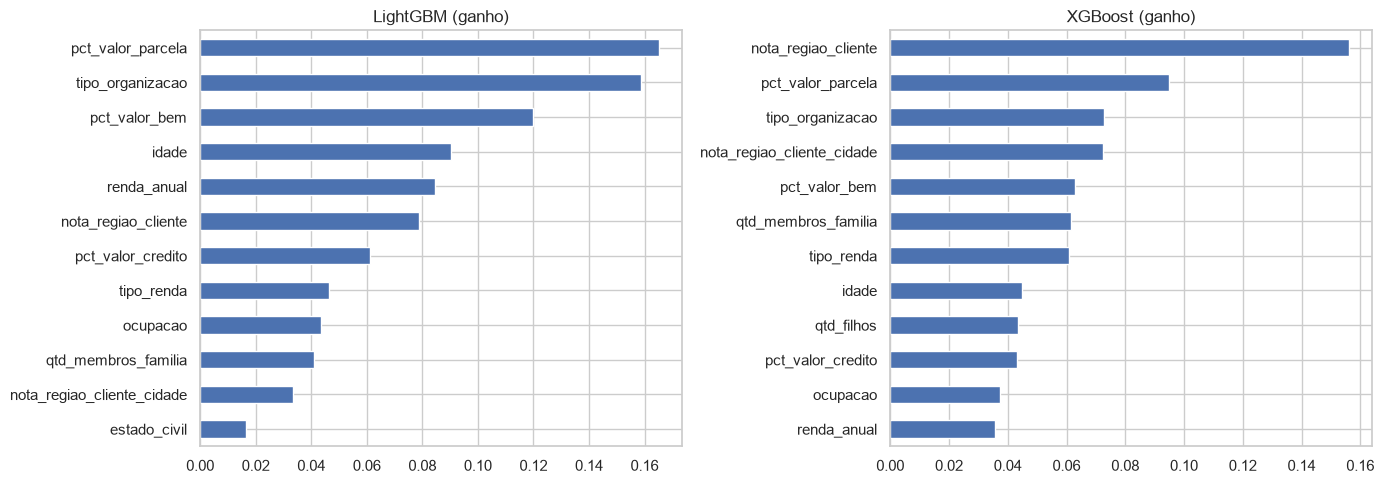

In [6]:
# Importância (ganho) no conjunto B
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp = pd.Series(MODELOS['lgbm', 'B'].booster_.feature_importance('gain'), index=ft.FEATURES['B']); (imp / imp.sum()).sort_values().tail(12).plot.barh(ax=ax[0], title='LightGBM (ganho)')
gx = MODELOS['xgb', 'B'].get_booster().get_score(importance_type='gain'); imp = pd.Series(gx); (imp / imp.sum()).sort_values().tail(12).plot.barh(ax=ax[1], title='XGBoost (ganho)')
plt.tight_layout(); plt.savefig(FIG / 'nb03_importancia_B.png', dpi=110); plt.show()

## 4. Critérios de adoção do B (definidos antes dos resultados, `docs/DECISOES.md` 1.10)
1. B supera o A na **validação e no teste**, com IC 95% do bootstrap pareado acima de zero em **AUC e F1**.
2. **PSI do score** do B entre o teste e a submissão < 0,25.
3. **Spearman** entre os scores de B e A na submissão ≥ 0,8.

Se algum falhar, o modelo final é o A. O C é só referência.

In [7]:
a_, b_, c_ = (ALG, 'A'), (ALG, 'B'), (ALG, 'C')
det = {}
for s in ['valid', 'teste']:
    d = bootstrap_pareado(Y[s], S[a_][s], S[b_][s], LIM[a_], LIM[b_], n_boot=1000)
    det[s] = d; print(f'B − A, {s}:'); display(d.round(4))
psi_b = psi(S[b_]['teste'], S[b_]['sub']); rho = spearmanr(S[b_]['sub'], S[a_]['sub'])[0]
crit = pd.DataFrame({'critério': ['1. ΔAUC > 0 (IC) em validação e teste', '1. ΔF1 > 0 (IC) em validação e teste', '2. PSI do score B (teste × submissão) < 0,25', '3. Spearman(B, A) na submissão ≥ 0,8'],
    'valor': [min(det[s].loc['auc', 'ic95_inf'] for s in det), min(det[s].loc['f1', 'ic95_inf'] for s in det), psi_b, rho],
    'passou': [all(det[s].loc['auc', 'ic95_inf'] > 0 for s in det), all(det[s].loc['f1', 'ic95_inf'] > 0 for s in det), psi_b < .25, rho >= .8]})
display(crit.round(4)); CONJ_FINAL = 'B' if crit.passou.all() else 'A'
print('conjunto final:', CONJ_FINAL)

B − A, valid:


,delta_medio,ic95_inf,ic95_sup
auc,0.0049,-0.0001,0.0100
recall,0.0017,-0.0052,0.0090
f1,-0.0057,-0.0132,0.0016


B − A, teste:


,delta_medio,ic95_inf,ic95_sup
auc,0.0090,0.0025,0.0154
recall,0.0014,-0.0074,0.0101
f1,-0.0000,-0.0090,0.0097


,critério,valor,passou
0,1. ΔAUC > 0 (IC) em validação e teste,-0.0001,False
1,1. ΔF1 > 0 (IC) em validação e teste,-0.0132,False
2,"2. PSI do score B (teste × submissão) < 0,25",0.0656,True
3,"3. Spearman(B, A) na submissão ≥ 0,8",0.8587,True


conjunto final: A


,AUC valid,AUC teste,F1 valid,F1 teste,score médio valid,score médio teste,score médio submissão,% submissão acima do limiar,PSI score teste×submissão
A,0.6992,0.6942,0.4786,0.4771,0.2224,0.2213,0.2616,0.1989,0.0674
B,0.7039,0.7032,0.4731,0.4769,0.2199,0.2178,0.2572,0.1974,0.0656
C,0.7067,0.7082,0.4739,0.4796,0.2121,0.2105,0.2280,0.1987,0.1517


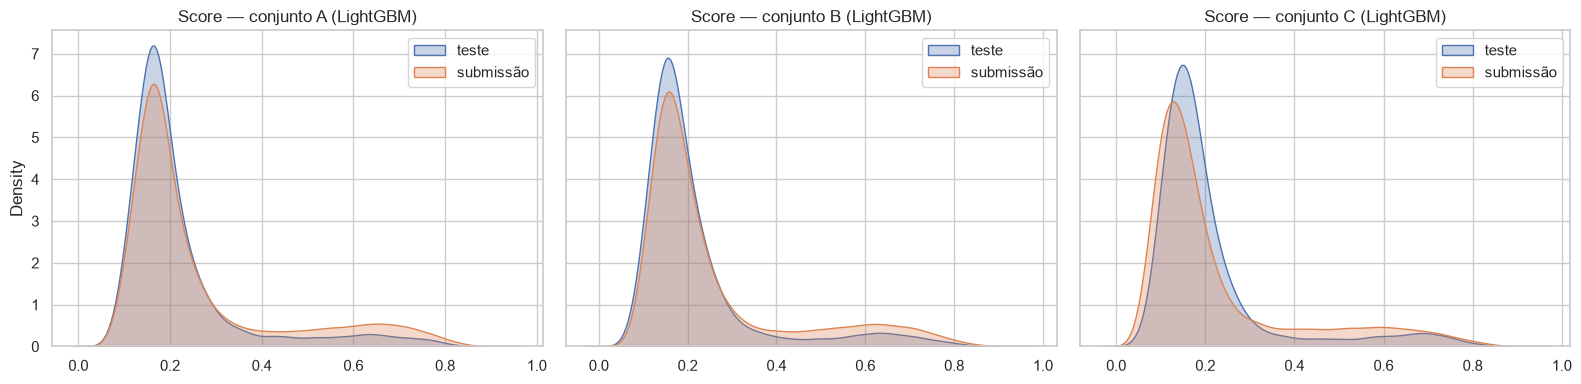

In [8]:
# Referência: o valor bruto (C) e o score médio na submissão
ref = pd.DataFrame({c: {'AUC valid': metricas(yv, S[ALG, c]['valid'], LIM[ALG, c])['auc'], 'AUC teste': metricas(yt, S[ALG, c]['teste'], LIM[ALG, c])['auc'],
                        'F1 valid': metricas(yv, S[ALG, c]['valid'], LIM[ALG, c])['f1'], 'F1 teste': metricas(yt, S[ALG, c]['teste'], LIM[ALG, c])['f1'],
                        'score médio valid': S[ALG, c]['valid'].mean(), 'score médio teste': S[ALG, c]['teste'].mean(), 'score médio submissão': S[ALG, c]['sub'].mean(),
                        '% submissão acima do limiar': (S[ALG, c]['sub'] >= LIM[ALG, c]).mean(), 'PSI score teste×submissão': psi(S[ALG, c]['teste'], S[ALG, c]['sub'])} for c in CONJ}).T
display(ref.round(4))
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, c in zip(ax, CONJ): sns.kdeplot(S[ALG, c]['teste'], ax=a, label='teste', fill=True, alpha=.3); sns.kdeplot(S[ALG, c]['sub'], ax=a, label='submissão', fill=True, alpha=.3); a.set_title(f'Score — conjunto {c} ({NOMES[ALG]})'); a.legend()
plt.tight_layout(); plt.savefig(FIG / 'nb03_score_teste_submissao.png', dpi=110); plt.show()

## 5. Target DPD > 30 e pesos de classe (modelo final, sem novo tuning)

In [9]:
y30 = {s: sp[s].target_dpd30 for s in SPL}; ok = {s: y30[s].notna() for s in SPL}
Xf = {s: XS[CONJ_FINAL][s][ok[s].values] for s in SPL}; yy = {s: y30[s][ok[s]].astype(int) for s in SPL}
nneg, npos = (yy['treino'] == 0).sum(), (yy['treino'] == 1).sum()
print(f'DPD > 30: treino n_neg/n_pos = {nneg / npos:.2f}')
r30 = []
for nome, peso in [('sem peso', 1.0), ('n_neg/n_pos', nneg / npos), ('√(n_neg/n_pos)', (nneg / npos) ** .5)]:
    m, _ = tr.treinar(ALG, T[ALG, CONJ_FINAL]['params'], T[ALG, CONJ_FINAL]['n_arvores'], Xf['treino'], yy['treino'], peso=peso)
    pv = m.predict_proba(Xf['valid'])[:, 1]; lim = limiar_max_f1(yy['valid'], pv)
    r30.append({'peso': nome, **{k: v for k, v in metricas(yy['valid'], pv, lim).items() if k in ('recall', 'f1', 'precision', 'auc', 'pr_auc', 'brier')}, 'score médio': pv.mean(), 'taxa real valid': yy['valid'].mean()})
display(pd.DataFrame(r30).set_index('peso').round(4))
m5 = metricas(yv, S[ALG, CONJ_FINAL]['valid'], LIM[ALG, CONJ_FINAL])
print('Referência (modelo DPD > 5, validação): recall', round(m5['recall'], 3), '| F1', round(m5['f1'], 3), '| AUC', round(m5['auc'], 3), '| PR-AUC', round(m5['pr_auc'], 3))

DPD > 30: treino n_neg/n_pos = 9.35


,recall,precision,f1,auc,pr_auc,brier,score médio,taxa real valid
peso,,,,,,,,
sem peso,0.3420,0.2652,0.2987,0.6499,0.1824,0.0737,0.0835,0.0845
n_neg/n_pos,0.3090,0.2800,0.2938,0.6507,0.1835,0.1761,0.3912,0.0845
√(n_neg/n_pos),0.3388,0.2597,0.2940,0.6477,0.1829,0.0894,0.1985,0.0845


Referência (modelo DPD > 5, validação): recall 0.386 | F1 0.479 | AUC 0.699 | PR-AUC 0.441


## 6. Artefatos para o nb04

In [10]:
joblib.dump({'ALG': ALG, 'CONJ_FINAL': CONJ_FINAL, 'LIM': LIM, 'T': T, 'S': S, 'cats': cats, 'features': ft.FEATURES[CONJ_FINAL],
             'modelo': MODELOS[ALG, CONJ_FINAL], 'ids': {s: sp[s][['id_contrato', 'id_cliente', 'safra']] for s in SPL}, 'ids_sub': bs.id_cliente}, MOD / 'resultado_nb03.joblib')
print('salvo:', MOD / 'resultado_nb03.joblib', '| final:', NOMES[ALG], 'conjunto', CONJ_FINAL)

salvo: C:\Projetos\dsaccelerator-tcc\data\modelos\resultado_nb03.joblib | final: LightGBM conjunto A


### Leitura
- LightGBM e XGBoost empatam (AUC ~0,70); fica o LightGBM, mais rápido. A logística (AUC ~0,61) mostra que há não linearidade útil.
- O conjunto B melhora o AUC no teste (+0,009, IC > 0), mas na validação o IC de ΔAUC inclui zero e o F1 não melhora. Pelo critério pré-registrado, **o final é o A**.
- O poder preditivo é modesto (AUC 0,70; F1 0,48): a política de crédito deve se apoiar em calibração e faixas de risco, não em um corte rígido.
- DPD > 30: pesos de classe não melhoram o ranking e distorcem as probabilidades; sem peso.
